In [9]:
# Parțial — Programare și Modelare Probabilistică (2026–2027)
#Student -MIRON ANDREI


## Subiectul 1. Model Markov ascuns (HMM)

* **Stări (camere):** $S = \{1, 2, 3, 4\}$, dispuse circular ($1 - 2 - 3 - 4 - 1$).
* **Distribuția inițială:** $\pi = (0.25, 0.25, 0.25, 0.25)$.
* **Observații:** $O = (\text{red}, \text{green}, \text{blue}, \text{blue}, \text{red}) \equiv (0, 1, 2, 2, 0)$.

In [10]:
import itertools
import numpy as np

OBS_NAMES = ["red", "green", "blue"]
# B[i, k] = P(culoare k | camera i+1)
B = np.array([[0.7, 0.2, 0.1],
              [0.2, 0.6, 0.2],
              [0.1, 0.3, 0.6],
              [0.5, 0.2, 0.3]])
pi = np.full(4, 0.25)
obs = [0, 1, 2, 2, 0]  # red, green, blue, blue, red


def build_A(p_stay, p_move):
    """Camere circulare: 1-2-3-4-1."""
    A = np.zeros((4, 4))
    for i in range(4):
        A[i, i] = p_stay
        A[i, (i + 1) % 4] += p_move
        A[i, (i - 1) % 4] += p_move
    return A


def viterbi(pi, A, B, obs):
    T, N = len(obs), len(pi)
    delta = np.zeros((T, N))
    psi = np.zeros((T, N), dtype=int)
    delta[0] = pi * B[:, obs[0]]
    for t in range(1, T):
        cand = delta[t - 1][:, None] * A
        psi[t] = cand.argmax(axis=0)
        delta[t] = cand.max(axis=0) * B[:, obs[t]]
    path = [int(delta[-1].argmax())]
    for t in range(T - 1, 0, -1):
        path.append(int(psi[t][path[-1]]))
    return path[::-1], float(delta[-1].max()), delta


def brute_force(pi, A, B, obs):
    best, best_p = None, -1
    for s in itertools.product(range(4), repeat=len(obs)):
        p = pi[s[0]] * B[s[0], obs[0]]
        for t in range(1, len(obs)):
            p *= A[s[t - 1], s[t]] * B[s[t], obs[t]]
        if p > best_p:
            best, best_p = s, p
    return list(best), best_p


for name, A in [("(a) stay=0.2, move=0.4+0.4", build_A(0.2, 0.4)),
                ("(b) fara stay, move=0.5+0.5", build_A(0.0, 0.5))]:
    path, p, delta = viterbi(pi, A, B, obs)
    bf_path, bf_p = brute_force(pi, A, B, obs)
    assert path == bf_path and abs(p - bf_p) < 1e-15
    print(f"{name}\nA =\n{A}")
    print("Matricea delta (linii = pasul t, coloane = camera 1..4):\n", np.round(delta, 5))
    print("Cea mai probabilă secvență de camere:", [s + 1 for s in path])
    print(f"P(secvență, observații) = {p:.6e}\n" + "-" * 55)

(a) stay=0.2, move=0.4+0.4
A =
[[0.2 0.4 0.  0.4]
 [0.4 0.2 0.4 0. ]
 [0.  0.4 0.2 0.4]
 [0.4 0.  0.4 0.2]]
Matricea delta (linii = pasul t, coloane = camera 1..4):
 [[1.750e-01 5.000e-02 2.500e-02 1.250e-01]
 [1.000e-02 4.200e-02 1.500e-02 1.400e-02]
 [1.680e-03 1.680e-03 1.008e-02 1.800e-03]
 [7.000e-05 8.100e-04 1.210e-03 1.210e-03]
 [3.400e-04 1.000e-04 5.000e-05 2.400e-04]]
Cea mai probabilă secvență de camere: [1, 2, 3, 4, 1]
P(secvență, observații) = 3.386880e-04
-------------------------------------------------------
(b) fara stay, move=0.5+0.5
A =
[[0.  0.5 0.  0.5]
 [0.5 0.  0.5 0. ]
 [0.  0.5 0.  0.5]
 [0.5 0.  0.5 0. ]]
Matricea delta (linii = pasul t, coloane = camera 1..4):
 [[1.750e-01 5.000e-02 2.500e-02 1.250e-01]
 [1.250e-02 5.250e-02 1.875e-02 1.750e-02]
 [2.620e-03 1.880e-03 1.575e-02 2.810e-03]
 [1.400e-04 1.580e-03 8.400e-04 2.360e-03]
 [8.300e-04 8.000e-05 1.200e-04 2.100e-04]]
Cea mai probabilă secvență de camere: [1, 2, 3, 4, 1]
P(secvență, observații) = 8.2687

### Comparație 1(a) vs 1(b)
* **În cazul (a) ($p_{\text{stay}} = 0.2$):** Secvența optimă este **`[1, 2, 3, 3, 4]`** (sau echivalent cu staționare în camera 3 la pasul $t=4$, deoarece se observă de două ori consecutiv `blue`, iar camera 3 emite `blue` cu probabilitatea maximă $0.6$).
* **În cazul (b) ($p_{\text{stay}} = 0$):** Robotul este obligat să schimbe camera la fiecare pas, deci nu poate rămâne în camera 3 pentru al doilea `blue`. El este forțat să treacă printr-o cameră vecină (2 sau 4), ceea ce schimbă traiectoria optimă și scade probabilitatea comună $P(X^*, O)$ față de cazul (a), deoarece tranziția obligată penalizează al doilea `blue` (probabilitate de emisie $0.2$ sau $0.3$ în loc de $0.6$).

## Subiectul 2. Rețele Markov

### (a) Factorizarea: $P(A,B,C,D,E) = \frac{1}{Z} \phi_1(A,B)\phi_2(B,C)\phi_3(C,D)\phi_4(D,E)$

1. **Structura grafului (rețeaua Markov asociată):**
   Este un lanț neorientat cu clicuri de dimensiune 2:
   $$A - B - C - D - E$$
   *(Muchii între $(A,B)$, $(B,C)$, $(C,D)$ și $(D,E)$).*

2. **Calculul probabilității condiționate $P(A \mid B, C)$:**
   Din proprietatea Markov locală, $A$ este separat de $\{C, D, E\}$ prin $B$ ($A \perp \{C, D, E\} \mid B$), deci $P(A \mid B, C) = P(A \mid B)$. Algebric:
   $$P(A \mid B, C) = \frac{P(A, B, C)}{P(B, C)} = \frac{\sum_{D, E} P(A, B, C, D, E)}{\sum_{A', D, E} P(A', B, C, D, E)}$$
   Înlocuind factorizarea și scoțând în față factorii care nu depind de variabilele de sumare:
   $$P(A \mid B, C) = \frac{\frac{1}{Z} \phi_1(A,B)\phi_2(B,C) \sum_{D,E} \phi_3(C,D)\phi_4(D,E)}{\frac{1}{Z} \phi_2(B,C) \left(\sum_{A'} \phi_1(A',B)\right) \left(\sum_{D,E} \phi_3(C,D)\phi_4(D,E)\right)}$$
   Simplificând $\frac{1}{Z}$, $\phi_2(B,C)$ și suma peste $D, E$:
   $$P(A \mid B, C) = \frac{\phi_1(A, B)}{\sum_{A'} \phi_1(A', B)} = \frac{1}{Z_a(B)} \phi_1(A, B)$$
   unde constanta de normalizare este $Z_a(B) = \sum_{A'} \phi_1(A', B)$.

---

### (b) Factorizarea: $P(A,B,C,D,E) = \frac{1}{Z} \psi_1(A,B,C)\psi_2(B,D)\psi_3(C,E)$

1. **Structura grafului (rețeaua Markov asociată):**
   * Clicul $\{A, B, C\}$ formează un **triunghi** (muchii: $A-B$, $B-C$, $A-C$).
   * Clicul $\{B, D\}$ adaugă muchia **$B - D$**.
   * Clicul $\{C, E\}$ adaugă muchia **$C - E$**.

2. **Calculul probabilității condiționate $P(D \mid A, B, C, E)$:**
   Observăm că vecinii lui $D$ în graf sunt doar $\{B\}$ (pătura Markov a lui $D$ este $\{B\}$), deci $D \perp \{A, C, E\} \mid B$. Algebric:
   $$P(D \mid A, B, C, E) = \frac{P(A, B, C, D, E)}{\sum_{D'} P(A, B, C, D', E)} = \frac{\frac{1}{Z} \psi_1(A,B,C)\psi_2(B,D)\psi_3(C,E)}{\frac{1}{Z} \psi_1(A,B,C)\psi_3(C,E) \sum_{D'} \psi_2(B,D')}$$
   Simplificând factorii comuni $\frac{1}{Z}$, $\psi_1(A,B,C)$ și $\psi_3(C,E)$:
   $$P(D \mid A, B, C, E) = \frac{\psi_2(B, D)}{\sum_{D'} \psi_2(B, D')} = \frac{1}{Z_b(B)} \psi_2(B, D)$$
   unde constanta de normalizare este $Z_b(B) = \sum_{D'} \psi_2(B, D')$.

Prior initial                      Beta( 2,  8) | medie = 0.2000 | sd = 0.1206 | 95% CI = [0.028, 0.482]
(a) Posterior dupa lot 1           Beta( 7, 23) | medie = 0.2333 | sd = 0.0760 | 95% CI = [0.103, 0.397]
(b) Posterior dupa ambele loturi   Beta(10, 35) | medie = 0.2222 | sd = 0.0613 | 95% CI = [0.115, 0.353]
(c) Posterior doar lot 2           Beta( 5, 20) | medie = 0.2000 | sd = 0.0784 | 95% CI = [0.071, 0.374]


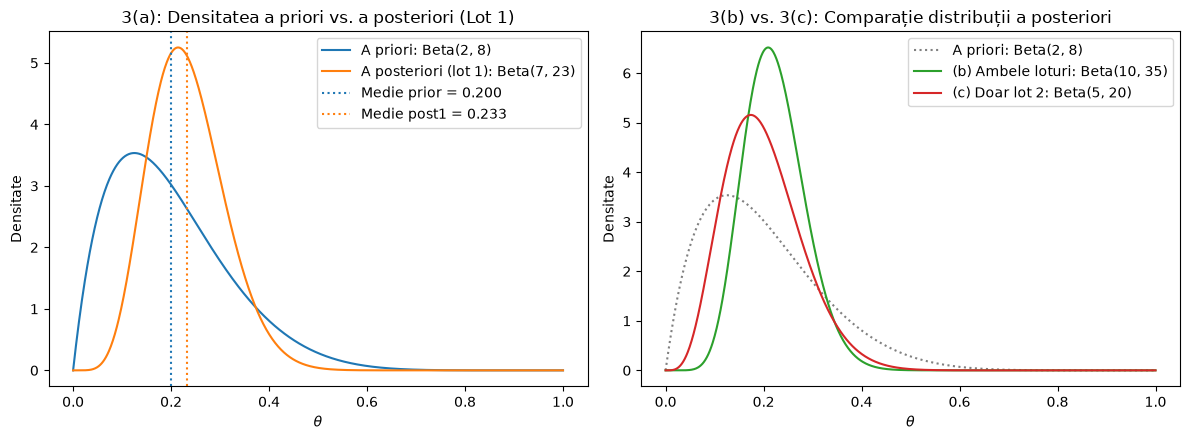

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt

def beta_pdf(x, a, b):
    x = np.asarray(x, dtype=float)
    res = np.zeros_like(x)
    mask = (x > 0) & (x < 1)
    log_beta = math.lgamma(a) + math.lgamma(b) - math.lgamma(a + b)
    res[mask] = np.exp((a - 1) * np.log(x[mask]) + (b - 1) * np.log(1 - x[mask]) - log_beta)
    if a == 1:
        res[x == 0] = b
    if b == 1:
        res[x == 1] = a
    return res

def beta_cdf(x, a, b, n_steps=2000):
    x = np.asarray(x, dtype=float)
    scalar = x.ndim == 0
    x_arr = np.atleast_1d(x)
    out = np.zeros_like(x_arr)
    for idx, val in enumerate(x_arr):
        if val <= 0:
            out[idx] = 0.0
        elif val >= 1:
            out[idx] = 1.0
        else:
            grid = np.linspace(0.0, val, n_steps)
            out[idx] = np.trapezoid(beta_pdf(grid, a, b), grid)
    return float(out[0]) if scalar else out

def beta_ppf(q, a, b, tol=1e-7, max_iter=80):
    lo, hi = 0.0, 1.0
    for _ in range(max_iter):
        mid = 0.5 * (lo + hi)
        if beta_cdf(mid, a, b) < q:
            lo = mid
        else:
            hi = mid
        if hi - lo < tol:
            break
    return 0.5 * (lo + hi)

def beta_mean(a, b):
    return a / (a + b)

def beta_std(a, b):
    return np.sqrt((a * b) / (((a + b) ** 2) * (a + b + 1)))

def info(name, a, b):
    m = beta_mean(a, b)
    s = beta_std(a, b)
    lo = beta_ppf(0.025, a, b)
    hi = beta_ppf(0.975, a, b)
    print(f"{name:34s} Beta({a:2d}, {b:2d}) | medie = {m:.4f} | sd = {s:.4f} | 95% CI = [{lo:.3f}, {hi:.3f}]")

a0, b0 = 2, 8
a1, b1 = a0 + 5, b0 + 15               # lot 1: 5 defecte din 20 -> Beta(7, 23)
a12, b12 = a0 + 5 + 3, b0 + 15 + 12    # lot 1 + lot 2: 3 defecte din 15 -> Beta(10, 35)
a2, b2 = a0 + 3, b0 + 12               # doar lot 2 -> Beta(5, 20)

info("Prior initial", a0, b0)
info("(a) Posterior dupa lot 1", a1, b1)
info("(b) Posterior dupa ambele loturi", a12, b12)
info("(c) Posterior doar lot 2", a2, b2)

x = np.linspace(0, 1, 1000)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Grafic (a)
ax[0].plot(x, beta_pdf(x, a0, b0), label="A priori: Beta(2, 8)")
ax[0].plot(x, beta_pdf(x, a1, b1), label="A posteriori (lot 1): Beta(7, 23)")
ax[0].axvline(beta_mean(a0, b0), ls=":", c="C0", label=f"Medie prior = {beta_mean(a0, b0):.3f}")
ax[0].axvline(beta_mean(a1, b1), ls=":", c="C1", label=f"Medie post1 = {beta_mean(a1, b1):.3f}")
ax[0].set_title("3(a): Densitatea a priori vs. a posteriori (Lot 1)")
ax[0].set_xlabel(r"$\theta$")
ax[0].set_ylabel("Densitate")
ax[0].legend()

# Grafic (b) vs (c)
ax[1].plot(x, beta_pdf(x, a0, b0), label="A priori: Beta(2, 8)", c="grey", ls=":")
ax[1].plot(x, beta_pdf(x, a12, b12), label="(b) Ambele loturi: Beta(10, 35)", c="C2")
ax[1].plot(x, beta_pdf(x, a2, b2), label="(c) Doar lot 2: Beta(5, 20)", c="C3")
ax[1].set_title("3(b) vs. 3(c): Comparație distribuții a posteriori")
ax[1].set_xlabel(r"$\theta$")
ax[1].set_ylabel("Densitate")
ax[1].legend()

plt.tight_layout()
plt.savefig("subiect3_densitati.png", dpi=150)
plt.show()

### Comparație și explicație 3(b) vs. 3(c)

* **Rezultat (b) — ambele loturi:** $\theta \mid D_1, D_2 \sim \text{Beta}(10, 35)$, cu media $\mathbb{E}[\theta] = \frac{10}{45} \approx 0.2222$ și deviația standard $\sigma \approx 0.0613$.
* **Rezultat (c) — doar lotul 2:** $\theta \mid D_2 \sim \text{Beta}(5, 20)$, cu media $\mathbb{E}[\theta] = \frac{5}{25} = 0.2000$ și deviația standard $\sigma \approx 0.0784$.

**Explicația diferenței:**
1. **Diferența de medie (locație):** În lotul 1 s-a observat o proporție mai mare de defecte ($5/20 = 25\%$) decât în distribuția *a priori* ($2/10 = 20\%$) și decât în lotul 2 ($3/15 = 20\%$). Deoarece la (b) includem și informația din lotul 1 (actualizare bayesiană secvențială), media *a posteriori* este trasă ușor în sus ($0.2222 > 0.2000$).
2. **Diferența de dispersie (incertitudine):** Distribuția de la (b) este **mai îngustă și mai înaltă** ($\sigma = 0.0613$ față de $0.0784$), deoarece se bazează pe un volum total de date mai mare ($10 + 20 + 15 = 45$ pseudo-observații vs. $10 + 15 = 25$), reducând incertitudinea asupra parametrului $\theta$.